# Project 21 — Flight Delay Prediction
## EDA Part 01: Target Definition + Target-Focused EDA

**Goal of this notebook:** decide *exactly* what we predict, at *what moment* we predict it, and
understand how the target behaves against features that are legitimately available at that moment.

Outline
1. Load data & recap of quality issues
2. Decision time + leakage audit (which columns are allowed)
3. Target definition (`arr_delay > 15 min`) — justification, threshold sensitivity, cancelled/diverted flights
4. Class balance
5. Target vs. pre-departure features (time, carrier, airport, route, distance, aircraft)
6. Statistical association (Chi-square / Cramér's V, mutual information)
7. Temporal drift & chronological split plan
8. Leakage-safe historical features (preview)
9. Summary of decisions → export

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.feature_selection import mutual_info_classif

SEED = 42
DATA = Path("../flights (1).csv")
FIG = Path("../figures/eda_part02"); FIG.mkdir(parents=True, exist_ok=True)
OUT = Path("../data_processed"); OUT.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

df = pd.read_csv(DATA)
df["time_hour"] = pd.to_datetime(df["time_hour"])
df["date"] = pd.to_datetime(df[["year", "month", "day"]])
print(df.shape)
df.head()

(336776, 22)


,id,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour,name,date
0,0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00,United Air Lines Inc.,2013-01-01
1,1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01 05:00:00,United Air Lines Inc.,2013-01-01
2,2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01 05:00:00,American Airlines Inc.,2013-01-01
3,3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01 05:00:00,JetBlue Airways,2013-01-01
4,4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01 06:00:00,Delta Air Lines Inc.,2013-01-01


## 1. Quick quality recap (relevant to the target)

In [2]:
na = df.isna().sum()
display(pd.DataFrame({"missing": na, "pct": (na / len(df) * 100).round(2)}).query("missing > 0"))
print("Unique values:", df[["carrier", "origin", "dest", "tailnum", "flight"]].nunique().to_dict())
print("Year values:", df["year"].unique())

,missing,pct
dep_time,8255,2.45
dep_delay,8255,2.45
arr_time,8713,2.59
arr_delay,9430,2.80
tailnum,2512,0.75
air_time,9430,2.80


Unique values: {'carrier': 16, 'origin': 3, 'dest': 105, 'tailnum': 4043, 'flight': 3844}
Year values: [2013]


**Reading:** missingness is *structured*, not random:
- `dep_time`/`dep_delay` missing ⇒ the flight **never departed (cancelled)**.
- departed but `arr_delay` missing ⇒ **diverted / no arrival record**.

These rows don't have an arrival delay, so we have to make an explicit decision about them for the target (see §3).
`year` is constant (2013), so we drop it as a feature.

In [3]:
df["status"] = np.select(
    [df["dep_time"].isna(), df["arr_delay"].isna()],
    ["cancelled", "diverted/no-arrival"],
    default="completed",
)
df["status"].value_counts().to_frame("flights").assign(pct=lambda t: (t.flights / len(df) * 100).round(2))

,flights,pct
status,,
completed,327346,97.20
cancelled,8255,2.45
diverted/no-arrival,1175,0.35


## 2. Decision time & leakage audit

The problem statement says: *"must not use post-departure information when making pre-departure predictions."*

**Chosen decision time:** at scheduling / before departure (e.g. the evening before, or at check-in).
So a feature is allowed only if it is known **before the aircraft leaves the gate**.

In [4]:
leak_table = pd.DataFrame([
    ("id", "row id", "DROP – identifier, no meaning"),
    ("year", "constant 2013", "DROP – no variance"),
    ("month, day", "calendar", "ALLOWED"),
    ("sched_dep_time, hour, minute, time_hour", "schedule", "ALLOWED"),
    ("sched_arr_time", "schedule", "ALLOWED"),
    ("carrier, name", "airline", "ALLOWED (name = duplicate of carrier)"),
    ("flight", "flight number", "ALLOWED (high cardinality)"),
    ("tailnum", "aircraft", "ALLOWED with care (assignment can change late)"),
    ("origin, dest, distance", "route", "ALLOWED"),
    ("dep_time", "actual departure", "LEAK – known only after departure"),
    ("dep_delay", "actual departure delay", "LEAK – known only after departure"),
    ("arr_time", "actual arrival", "LEAK – target-derived"),
    ("air_time", "actual flight time", "LEAK – known only after landing"),
    ("arr_delay", "actual arrival delay", "TARGET SOURCE"),
], columns=["column(s)", "meaning", "decision"])
leak_table

,column(s),meaning,decision
0,id,row id,"DROP – identifier, no meaning"
1,year,constant 2013,DROP – no variance
2,"month, day",calendar,ALLOWED
3,"sched_dep_time, hour, minute, time_hour",schedule,ALLOWED
4,sched_arr_time,schedule,ALLOWED
5,"carrier, name",airline,ALLOWED (name = duplicate of carrier)
6,flight,flight number,ALLOWED (high cardinality)
7,tailnum,aircraft,ALLOWED with care (assignment can change late)
8,"origin, dest, distance",route,ALLOWED
9,dep_time,actual departure,LEAK – known only after departure


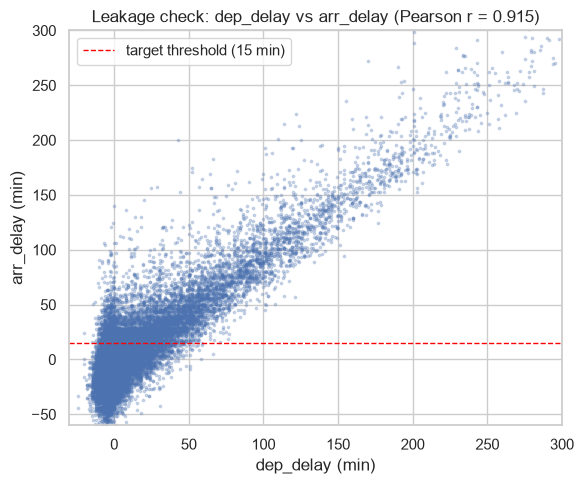

In [5]:
# Why dep_delay MUST be excluded: it almost is the target.
c = df.dropna(subset=["dep_delay", "arr_delay"]).sample(30000, random_state=SEED)
r = df[["dep_delay", "arr_delay"]].dropna().corr().iloc[0, 1]
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(c["dep_delay"], c["arr_delay"], s=3, alpha=0.25)
ax.set(xlim=(-30, 300), ylim=(-60, 300), xlabel="dep_delay (min)", ylabel="arr_delay (min)",
       title=f"Leakage check: dep_delay vs arr_delay (Pearson r = {r:.3f})")
ax.axhline(15, color="red", ls="--", lw=1, label="target threshold (15 min)")
ax.legend()
savefig("01_leakage_dep_vs_arr")

**Reading:** `dep_delay` correlates with `arr_delay` at r ≈ 0.91. A model that sees it would look excellent
(ROC AUC in the high 0.9s) but would be useless before departure. This is the single biggest leakage risk
in this dataset, so **`dep_time`, `dep_delay`, `arr_time` and `air_time` are removed from every model.**

## 3. Target definition

**Target:** `delayed = 1 if arr_delay > 15 minutes else 0`

Why 15 minutes?
- It is the **official US BTS / FAA definition** of an "on-time" flight (arrival within 15 min of schedule).
- It is the standard used in the BTS On-Time Performance documentation, which is a suggested pre-read.
- It ignores small delays that schedule padding usually absorbs.

### 3a. Distribution of the raw arrival delay

count    327346.0
mean          6.9
std          44.6
min         -86.0
5%          -32.0
25%         -17.0
50%          -5.0
75%          14.0
90%          52.0
95%          91.0
99%         190.0
max        1272.0
Name: arr_delay, dtype: float64
skewness: 3.72


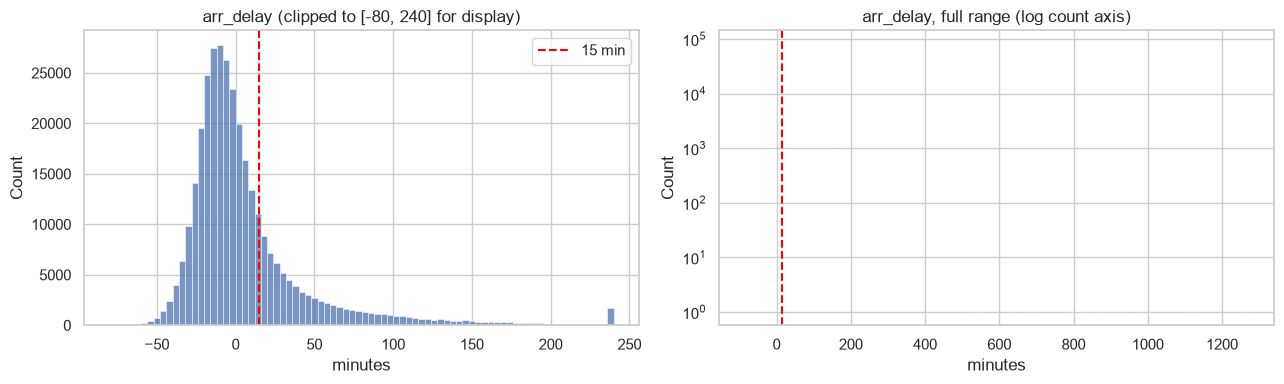

In [6]:
done = df[df["status"] == "completed"].copy()
print(done["arr_delay"].describe(percentiles=[.05, .25, .5, .75, .9, .95, .99]).round(1))
print("skewness:", round(done["arr_delay"].skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(done["arr_delay"].clip(-80, 240), bins=80, ax=axes[0])
axes[0].axvline(15, color="red", ls="--", label="15 min")
axes[0].set(title="arr_delay (clipped to [-80, 240] for display)", xlabel="minutes"); axes[0].legend()
sns.histplot(done["arr_delay"], bins=120, ax=axes[1], log_scale=(False, True))
axes[1].axvline(15, color="red", ls="--")
axes[1].set(title="arr_delay, full range (log count axis)", xlabel="minutes")
savefig("02_arr_delay_distribution")

**Reading:** the median flight arrives *early*, but there is a very long right tail (some delays are 15+ hours).
That heavy tail is another reason to use a **binary target** rather than regressing raw minutes: a few extreme
values would dominate MSE.

### 3b. Threshold sensitivity — how the positive rate changes with the cutoff

,threshold_min,positive_rate_%,n_positive
0,0,40.63,133004
1,15,23.71,77630
2,30,15.73,51499
3,45,11.33,37074
4,60,8.49,27789
5,120,3.07,10034


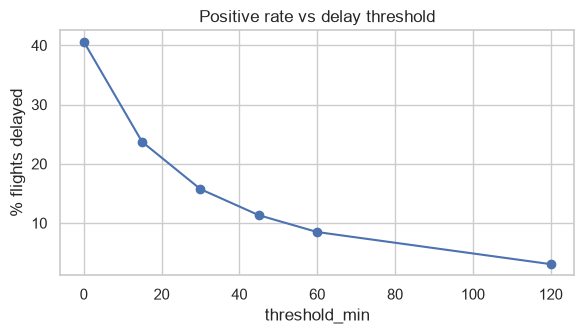

In [7]:
thr = pd.DataFrame({"threshold_min": [0, 15, 30, 45, 60, 120]})
thr["positive_rate_%"] = [round((done["arr_delay"] > t).mean() * 100, 2) for t in thr["threshold_min"]]
thr["n_positive"] = [int((done["arr_delay"] > t).sum()) for t in thr["threshold_min"]]
display(thr)
ax = thr.plot(x="threshold_min", y="positive_rate_%", marker="o", legend=False, figsize=(6, 3.5))
ax.set(ylabel="% flights delayed", title="Positive rate vs delay threshold")
savefig("03_threshold_sensitivity")

**Reading:** 15 min gives roughly a 76/24 split. That's imbalanced but still trainable without resampling.
Higher thresholds (60 min ≈ 8%) are a possible **ablation** for Phase 2, since they target "substantial" delays.

### 3c. What do we do with cancelled and diverted flights?

| Option | Pros | Cons |
|---|---|---|
| **A. Exclude** (chosen) | Target is precisely defined ("arrival delay > 15 min") | Ignores the worst disruptions |
| B. Label as delayed (1) | Captures operational disruption | Mixes two different events; cancellations are driven by weather/ops decisions |

**Decision:** Option A for the main target. We report cancellations separately as a limitation, and keep a
`cancelled` flag so Option B can be run as a sensitivity check.

,flights,cancelled
date,,
2013-02-09,684,57.46
2013-02-08,930,50.75
2013-05-23,988,22.37
2013-12-10,943,21.63
2013-09-12,992,19.35
2013-03-06,972,18.52
2013-03-08,979,18.39
2013-12-14,692,18.06


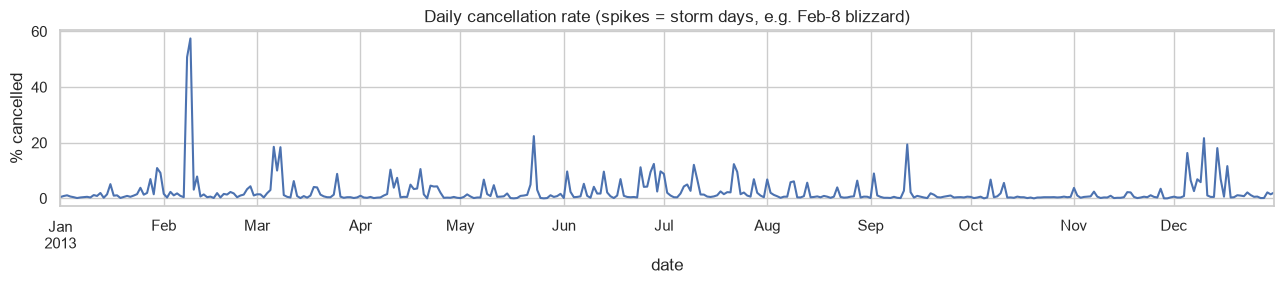

In [8]:
# Cancellations are NOT random — they cluster on certain days (weather events)
daily = df.groupby("date").agg(flights=("id", "size"),
                               cancelled=("status", lambda s: (s == "cancelled").mean() * 100))
top = daily.sort_values("cancelled", ascending=False).head(8)
display(top.round(2))
fig, ax = plt.subplots(figsize=(13, 3))
daily["cancelled"].plot(ax=ax)
ax.set(ylabel="% cancelled", title="Daily cancellation rate (spikes = storm days, e.g. Feb-8 blizzard)")
savefig("04_daily_cancellation_rate")

In [9]:
done["delayed"] = (done["arr_delay"] > 15).astype(int)
df["delayed"] = np.where(df["status"] == "completed", (df["arr_delay"] > 15).astype(float), np.nan)
df["cancelled"] = (df["status"] == "cancelled").astype(int)
print("Rows with a valid target:", len(done), f"({len(done)/len(df)*100:.2f}% of all flights)")

Rows with a valid target: 327346 (97.20% of all flights)


## 4. Class balance

delayed
on-time (0)    249716
delayed (1)     77630
Name: count, dtype: int64
Positive rate = 0.2371 | imbalance ratio = 3.22 : 1


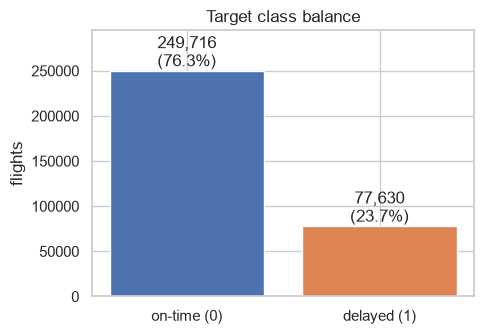

In [10]:
vc = done["delayed"].value_counts().sort_index()
pr = vc[1] / vc.sum()
print(vc.rename({0: "on-time (0)", 1: "delayed (1)"}))
print(f"Positive rate = {pr:.4f} | imbalance ratio = {vc[0]/vc[1]:.2f} : 1")
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["on-time (0)", "delayed (1)"], vc.values, color=["#4C72B0", "#DD8452"])
for i, v in enumerate(vc.values): ax.text(i, v, f"{v:,}\n({v/vc.sum():.1%})", ha="center", va="bottom")
ax.set(title="Target class balance", ylabel="flights"); ax.set_ylim(0, vc.max() * 1.18)
savefig("05_class_balance")

**Implications for modelling:**
- Accuracy is misleading: always predicting "on-time" scores ~76%. So we use **PR AUC** (baseline = positive rate ≈ 0.24),
  **ROC AUC**, **recall at a fixed precision**, and **calibration**, as the problem statement asks.
- Use `class_weight` / `pos_weight ≈ 3.2` (or plain BCE + threshold tuning), fit **on training data only**.

## 5. Target vs. pre-departure features

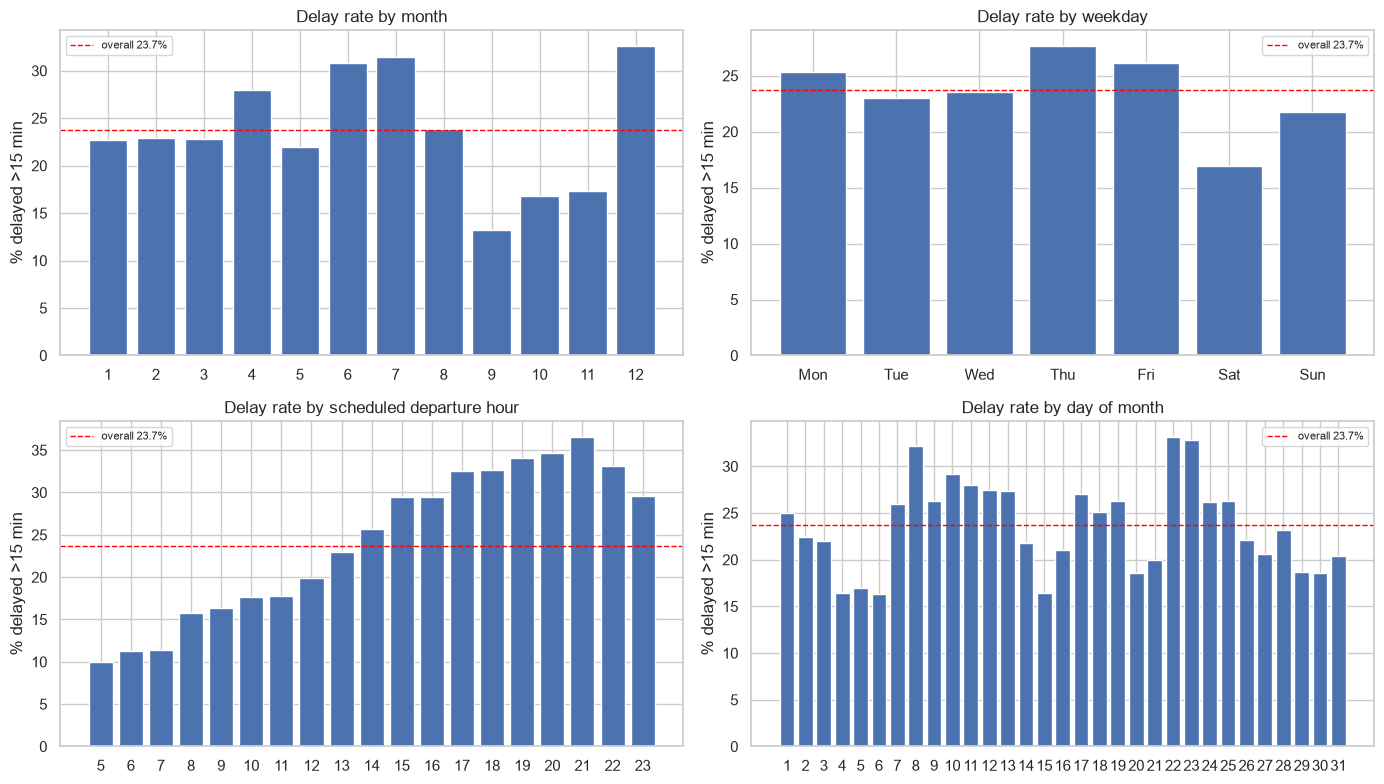

In [11]:
def rate_plot(col, ax, order=None, min_n=0, rot=0, title=None):
    g = done.groupby(col)["delayed"].agg(["mean", "size"])
    g = g[g["size"] >= min_n]
    if order is not None: g = g.reindex(order)
    ax.bar(g.index.astype(str), g["mean"] * 100, color="#4C72B0")
    ax.axhline(pr * 100, color="red", ls="--", lw=1, label=f"overall {pr:.1%}")
    ax.set(ylabel="% delayed >15 min", title=title or f"Delay rate by {col}")
    ax.tick_params(axis="x", rotation=rot); ax.legend(fontsize=8)
    return g

done["weekday"] = done["date"].dt.day_name().str[:3]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
rate_plot("month", axes[0, 0])
rate_plot("weekday", axes[0, 1], order=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
rate_plot("hour", axes[1, 0], min_n=100, title="Delay rate by scheduled departure hour")
rate_plot("day", axes[1, 1], title="Delay rate by day of month")
savefig("06_target_vs_time")

**Reading:**
- **Hour of day is the strongest time signal**: early-morning flights (~10% delayed) vs evening (~35%).
  Delays *propagate* through the day as aircraft rotations fall behind.
- **Season:** peaks in Jun–Jul (summer thunderstorms) and Dec (holidays/winter); Sep–Nov are the calmest.
- Day-of-month mostly reflects specific bad-weather days, so it doesn't generalise and shouldn't be used as a raw feature.

⇒ Encode hour/month/weekday **cyclically** (sin/cos), or as embeddings for the DL model.

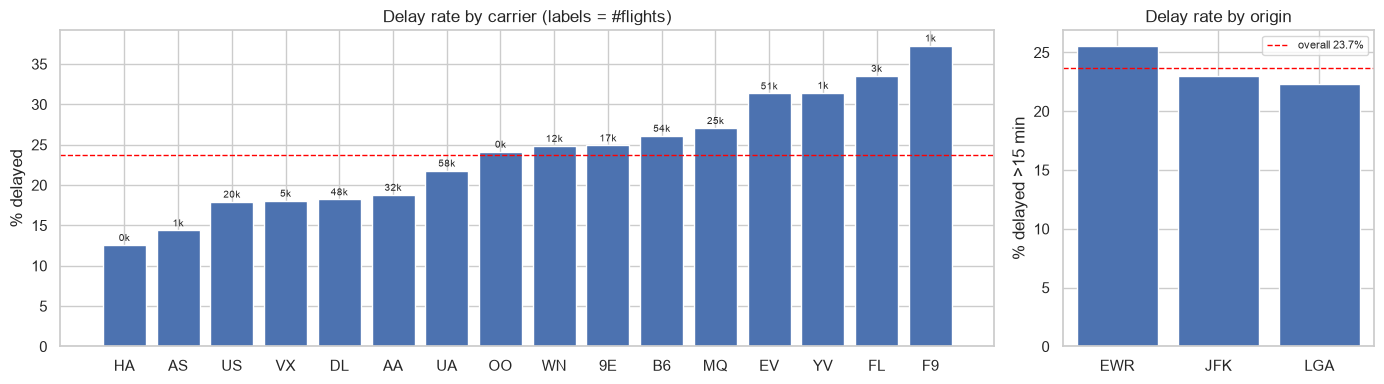

,name,flights,delay_rate
carrier,,,
F9,Frontier Airlines Inc.,681,0.373
FL,AirTran Airways Corporation,3175,0.335
YV,Mesa Airlines Inc.,544,0.314
EV,ExpressJet Airlines Inc.,51108,0.314
MQ,Envoy Air,25037,0.271
B6,JetBlue Airways,54049,0.261
9E,Endeavor Air Inc.,17294,0.249
WN,Southwest Airlines Co.,12044,0.249
OO,SkyWest Airlines Inc.,29,0.241


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [3, 1]})
g = done.groupby("carrier")["delayed"].agg(["mean", "size"]).sort_values("mean")
axes[0].bar(g.index, g["mean"] * 100)
for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
    axes[0].text(i, m * 100 + 0.5, f"{n/1000:.0f}k", ha="center", fontsize=7)
axes[0].axhline(pr * 100, color="red", ls="--", lw=1)
axes[0].set(title="Delay rate by carrier (labels = #flights)", ylabel="% delayed")
rate_plot("origin", axes[1])
savefig("07_target_vs_carrier_origin")
display(done.groupby("carrier").agg(name=("name", "first"), flights=("id", "size"),
        delay_rate=("delayed", "mean")).sort_values("delay_rate", ascending=False).round(3))

**Reading:** carriers differ a lot (roughly 2×–3× between the best and worst), but some carriers have very few flights
(OO has only 29, and HA/YV/F9 have under 700 each), so their rates are noisy. Use **smoothed target encoding** for tree models and **learned embeddings**
for the MLP, as the problem statement suggests. The three origin airports differ less than carriers do.

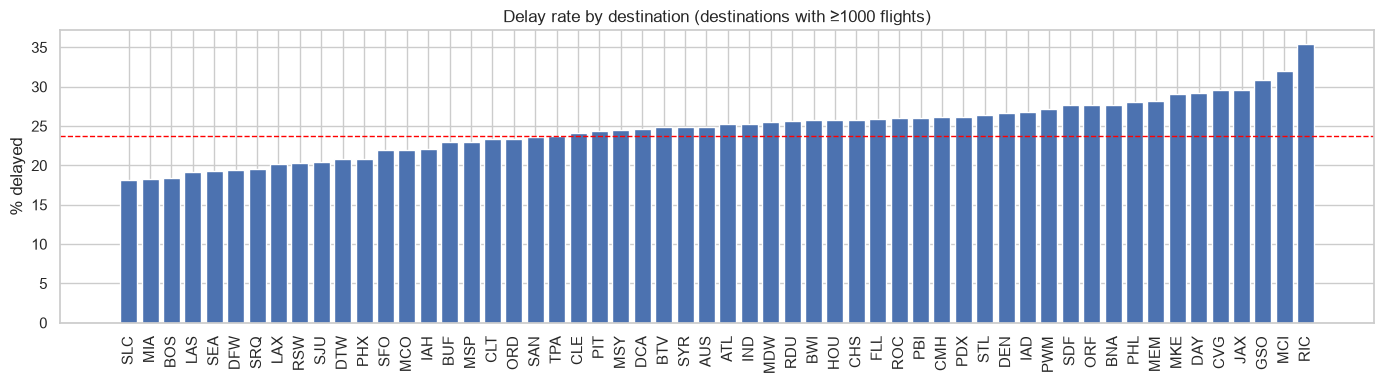

Destinations: 104 | with <100 flights: 12


In [13]:
dest_stats = done.groupby("dest")["delayed"].agg(rate="mean", n="size")
big = dest_stats[dest_stats["n"] >= 1000].sort_values("rate")
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(big.index, big["rate"] * 100); ax.axhline(pr * 100, color="red", ls="--", lw=1)
ax.set(title="Delay rate by destination (destinations with ≥1000 flights)", ylabel="% delayed")
ax.tick_params(axis="x", rotation=90)
savefig("08_target_vs_dest")
print("Destinations:", len(dest_stats), "| with <100 flights:", (dest_stats["n"] < 100).sum())

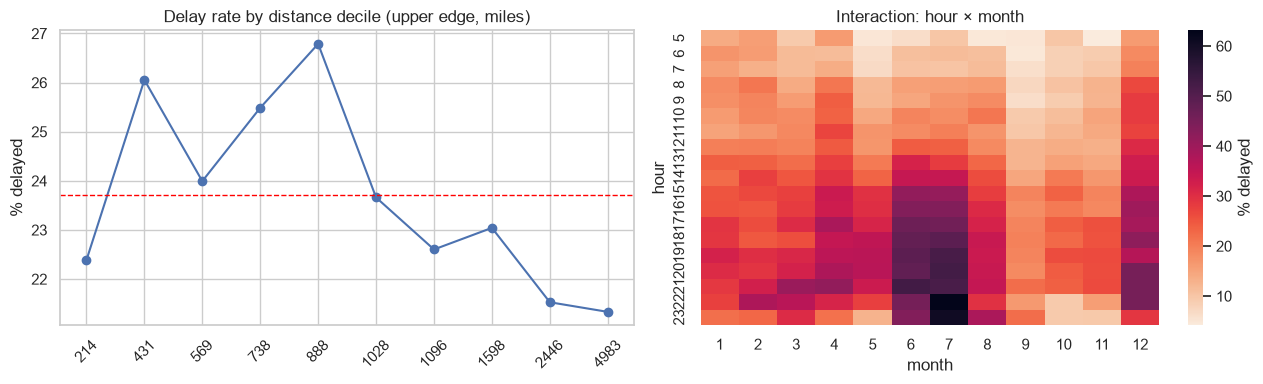

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
done["dist_bin"] = pd.qcut(done["distance"], 10, duplicates="drop")
g = done.groupby("dist_bin", observed=True)["delayed"].mean() * 100
axes[0].plot(range(len(g)), g.values, marker="o")
axes[0].set_xticks(range(len(g))); axes[0].set_xticklabels([f"{int(i.right)}" for i in g.index], rotation=45)
axes[0].axhline(pr * 100, color="red", ls="--", lw=1)
axes[0].set(title="Delay rate by distance decile (upper edge, miles)", ylabel="% delayed")

# Hour x Month interaction heatmap
hm = done.pivot_table(index="hour", columns="month", values="delayed", aggfunc="mean") * 100
sns.heatmap(hm.loc[5:23], cmap="rocket_r", ax=axes[1], cbar_kws={"label": "% delayed"})
axes[1].set(title="Interaction: hour × month")
savefig("09_distance_and_hour_month")

**Reading:** distance has a weak, non-monotonic relationship with delay. The **hour × month heatmap shows an interaction**:
summer and December evenings are far worse than the hour and month effects added together would predict. Linear models
miss this; trees and an MLP can learn it. This is one of the gaps the Phase 2 DL model is meant to address.

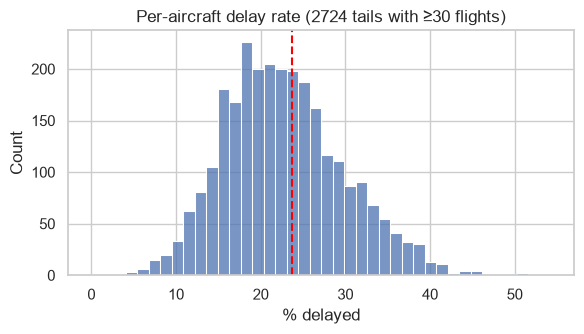

Missing tailnum among completed flights: 0


In [15]:
# Aircraft (tailnum): does the same plane have a persistent delay tendency?
tail = done.dropna(subset=["tailnum"]).groupby("tailnum")["delayed"].agg(rate="mean", n="size")
tail = tail[tail["n"] >= 30]
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.histplot(tail["rate"] * 100, bins=40, ax=ax)
ax.axvline(pr * 100, color="red", ls="--")
ax.set(title=f"Per-aircraft delay rate ({len(tail)} tails with ≥30 flights)", xlabel="% delayed")
savefig("10_tailnum_rate")
print("Missing tailnum among completed flights:", done["tailnum"].isna().sum())

## 6. Statistical association with the target

- **Cramér's V** (from a Chi-square test) for categorical features: 0 = no association, 1 = perfect.
- **Mutual information** captures non-linear dependence for all features.

Both are computed on a training-period subset (Jan–Aug), so test-period information doesn't influence feature choices.

In [16]:
train_like = done[done["month"] <= 8]

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, dof, _ = chi2_contingency(ct)
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1))), p

rows = []
for col in ["hour", "month", "weekday", "carrier", "origin", "dest", "flight", "tailnum"]:
    s = train_like.dropna(subset=[col])
    v, p = cramers_v(s[col], s["delayed"])
    rows.append((col, s[col].nunique(), round(v, 4), p))
assoc = pd.DataFrame(rows, columns=["feature", "n_levels", "cramers_v", "chi2_p"]).sort_values("cramers_v", ascending=False)
assoc

,feature,n_levels,cramers_v,chi2_p
6,flight,3258,0.2725,0.000000e+00
0,hour,19,0.2163,0.000000e+00
7,tailnum,3909,0.1942,2.115040e-307
3,carrier,16,0.1216,0.000000e+00
5,dest,102,0.0995,0.000000e+00
2,weekday,7,0.0850,0.000000e+00
1,month,8,0.0838,0.000000e+00
4,origin,3,0.0383,6.482059e-70


⚠️ **Caution for the viva:** Cramér's V is inflated for very high-cardinality features (`tailnum`, `flight`), because
with thousands of levels it partly measures noise. Those features need smoothing or regularised embeddings, and their value
should be confirmed on a **later time period**, not on the data used to compute it.

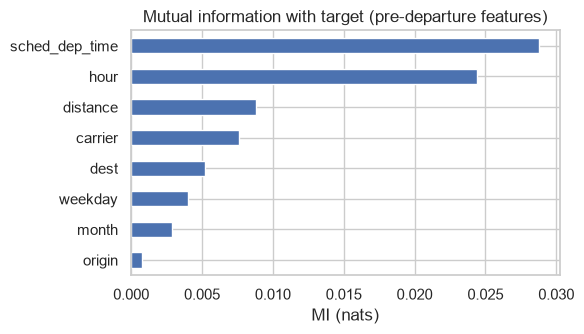

In [17]:
s = train_like.sample(80000, random_state=SEED)
X = pd.DataFrame({
    "hour": s["hour"], "month": s["month"], "weekday": s["date"].dt.weekday,
    "distance": s["distance"], "sched_dep_time": s["sched_dep_time"],
    "carrier": s["carrier"].astype("category").cat.codes,
    "origin": s["origin"].astype("category").cat.codes,
    "dest": s["dest"].astype("category").cat.codes,
})
discrete = [c != "distance" and c != "sched_dep_time" for c in X.columns]
mi = mutual_info_classif(X, s["delayed"], discrete_features=discrete, random_state=SEED)
mi = pd.Series(mi, index=X.columns).sort_values()
ax = mi.plot.barh(figsize=(6, 3.5), title="Mutual information with target (pre-departure features)")
ax.set_xlabel("MI (nats)")
savefig("11_mutual_information")

## 7. Temporal drift & chronological split

The problem statement asks us to **split by date**. A random split would leak information: flights on the same storm day
are strongly correlated, so the model would effectively see the test day during training.

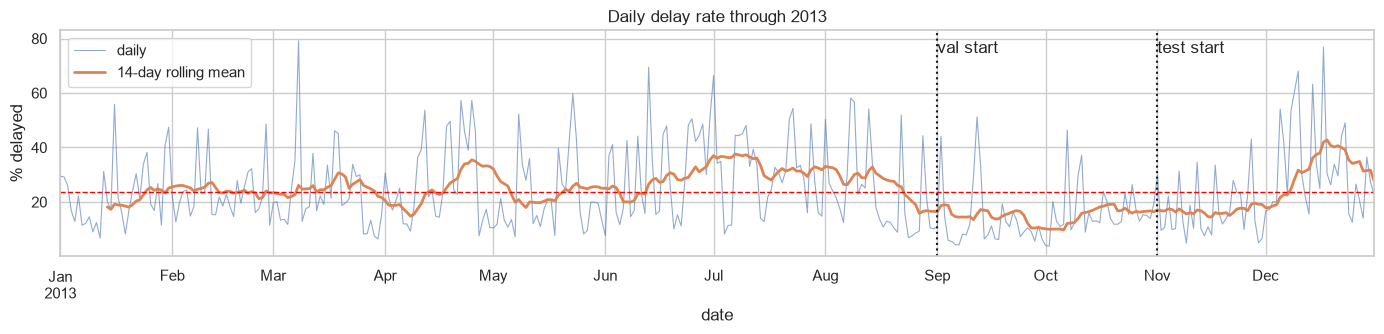

In [18]:
daily_rate = done.groupby("date")["delayed"].mean() * 100
fig, ax = plt.subplots(figsize=(14, 3.5))
daily_rate.plot(ax=ax, lw=0.8, alpha=0.6, label="daily")
daily_rate.rolling(14).mean().plot(ax=ax, lw=2, label="14-day rolling mean")
ax.axhline(pr * 100, color="red", ls="--", lw=1)
for d, lab in [("2013-09-01", "val start"), ("2013-11-01", "test start")]:
    ax.axvline(pd.Timestamp(d), color="k", ls=":"); ax.text(pd.Timestamp(d), ax.get_ylim()[1] * 0.9, lab)
ax.set(title="Daily delay rate through 2013", ylabel="% delayed"); ax.legend()
savefig("12_daily_delay_rate")

In [19]:
# Autocorrelation: today's delay rate tells us a lot about tomorrow's -> argument for using *past-day* features
print("Lag-1 day autocorrelation of daily delay rate:", round(daily_rate.autocorr(1), 3))
print("Lag-7 day autocorrelation:", round(daily_rate.autocorr(7), 3))

Lag-1 day autocorrelation of daily delay rate: 0.395
Lag-7 day autocorrelation: 0.113


In [20]:
split = np.select([done["month"] <= 8, done["month"] <= 10], ["train (Jan–Aug)", "val (Sep–Oct)"], "test (Nov–Dec)")
done["split"] = split
summary = done.groupby("split", sort=False).agg(flights=("id", "size"), positive_rate=("delayed", "mean"),
                                                 start=("date", "min"), end=("date", "max"))
summary["share_%"] = (summary["flights"] / len(done) * 100).round(1)
summary.round(4)

,flights,positive_rate,start,end,share_%
split,,,,,
train (Jan–Aug),217727,0.2561,2013-01-01,2013-08-31,66.5
val (Sep–Oct),55628,0.1505,2013-09-01,2013-10-31,17.0
test (Nov–Dec),53991,0.2499,2013-11-01,2013-12-31,16.5


**Reading / decision:**
- Proposed split: **train = Jan–Aug, validation = Sep–Oct, test = Nov–Dec** (strictly chronological).
- The positive rate **shifts between splits** (Sep–Oct is unusually calm and December is bad). That is real-world drift:
  PR AUC baselines differ per split, so we always report the split's own positive rate next to PR AUC.
- Calibration has to be checked on the test period, because probabilities trained on summer may be miscalibrated in winter.
- Optional ablation: a rolling-origin backtest (train up to month *m*, test month *m+1*).

## 8. Leakage-safe historical features (preview)

The problem statement asks for *"historical airport features using past dates only"*. Example: each origin's delay rate
over the **previous 7 days**, using `shift(1)` so the current day is never included.

In [21]:
od = done.groupby(["origin", "date"])["delayed"].agg(["sum", "size"]).reset_index().sort_values(["origin", "date"])
for k in ["sum", "size"]:
    od[f"{k}_7d"] = od.groupby("origin")[k].transform(lambda s: s.shift(1).rolling(7, min_periods=1).sum())
od["origin_rate_prev7d"] = od["sum_7d"] / od["size_7d"]
od["today_rate"] = od["sum"] / od["size"]
print("corr(prev-7-day origin rate, today's rate):",
      round(od[["origin_rate_prev7d", "today_rate"]].corr().iloc[0, 1], 3))
od[["origin", "date", "today_rate", "origin_rate_prev7d"]].dropna().head(10)

corr(prev-7-day origin rate, today's rate): 0.294


,origin,date,today_rate,origin_rate_prev7d
1,EWR,2013-01-02,0.413490,0.383333
2,EWR,2013-01-03,0.283988,0.399376
3,EWR,2013-01-04,0.175074,0.360082
4,EWR,2013-01-05,0.122363,0.312452
5,EWR,2013-01-06,0.314381,0.283312
6,EWR,2013-01-07,0.154971,0.288347
7,EWR,2013-01-08,0.178788,0.267490
8,EWR,2013-01-09,0.220896,0.238611
9,EWR,2013-01-10,0.122449,0.208955
10,EWR,2013-01-11,0.141593,0.184435


This feature has a modest positive correlation with the current day and is computed **only from strictly earlier dates**,
so it is valid at decision time. Feature engineering (next part) will extend it to carrier, destination and route.

## 9. Summary of decisions

| Item | Decision |
|---|---|
| Decision time | Before departure (scheduling time) |
| Target | `delayed = 1 if arr_delay > 15 min` (BTS on-time standard) |
| Cancelled / diverted | Excluded from target; `cancelled` flag kept for sensitivity analysis |
| Class balance | ≈ 76 / 24, so use PR AUC, ROC AUC, recall@precision, calibration; no accuracy |
| Dropped (leakage) | `dep_time`, `dep_delay`, `arr_time`, `air_time`, (`arr_delay` after target creation) |
| Dropped (useless) | `id`, `year`, `name` (duplicate of carrier) |
| Key signals | scheduled hour ≫ carrier > destination > weekday ≈ month (Cramér's V); hour×month interaction |
| High-cardinality | `dest` (105), `tailnum` (~4k), `flight` → smoothed target encoding (AML) / embeddings (DL) |
| Split | Chronological: train Jan–Aug, val Sep–Oct, test Nov–Dec |
| Historical features | Past-date-only rolling rates (`shift(1)`) |

In [22]:
keep = ["id", "date", "month", "day", "hour", "minute", "sched_dep_time", "sched_arr_time", "time_hour",
        "carrier", "flight", "tailnum", "origin", "dest", "distance", "status", "cancelled", "delayed"]
out = df[keep].copy()
out["weekday"] = out["date"].dt.weekday
out["split"] = np.select([out["month"] <= 8, out["month"] <= 10], ["train", "val"], "test")
out.to_csv(OUT / "flights_target.csv.gz", index=False, compression="gzip")
print("Saved", OUT / "flights_target.csv.gz", out.shape)
print("Figures saved to", FIG.resolve())

Saved ../data_processed/flights_target.csv.gz (336776, 20)
Figures saved to /Users/khushijain/Desktop/Aml/figures/eda_part02
